# Member stats 

This notebook checks the member-level table before building clan or matchup features. The main things to verify here are simple but important: each clan should have six members, IDs should line up with the match table, numeric fields should be sane.


In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

TRAIN_DATA_PATH = Path("../data/train")

members = pd.read_csv(TRAIN_DATA_PATH / "member_stats_training.csv")
matches = pd.read_csv(TRAIN_DATA_PATH / "clan_matches_training.csv")

print("members:", members.shape)
print("matches:", matches.shape)

display(members.sample(5, random_state=42))


members: (291456, 15)
matches: (24288, 5)


,clan_id,user_id,days_active_last_28_days,days_active_last_7_days,days_since_last_active,registration_country,registration_platform_specific,cohort_day,training_count_last_28_days,is_payer_lifetime,dynamic_payment_segment,clan_multiplier,avg_stars_top_11_players,avg_stars_top_3_players,avg_training_bonus
43672,clan_25863,user_43673,3,0,23,France,Android Phone,216,4,False,0) NonPayer,3,4.186727,4.921289,0.0
255587,clan_46868,user_255588,27,7,0,Morocco,Android Phone,1680,97,True,1) ExPayer,3,6.145006,6.870000,13.0
253820,clan_47314,user_253821,28,7,0,Netherlands,iOS Phone,3269,555,True,2) Minnow,3,7.592897,7.894223,13.0
215993,clan_46914,user_215994,28,7,0,Portugal,Android Phone,1328,126,False,0) NonPayer,3,6.446606,7.042445,12.0
267040,clan_34136,user_267041,28,7,0,Portugal,iOS Tablet,133,118,True,3) Dolphin,3,7.243285,7.899867,13.5


## Column groups

Keeping the feature groups explicit makes later aggregation code easier to audit. The numeric columns are the ones used for most roster-strength and activity features.


In [17]:
id_cols = ["clan_id", "user_id"]

numeric_cols = [
    "days_active_last_28_days",
    "days_active_last_7_days",
    "days_since_last_active",
    "cohort_day",
    "training_count_last_28_days",
    "clan_multiplier",
    "avg_stars_top_11_players",
    "avg_stars_top_3_players",
    "avg_training_bonus",
]

categorical_cols = [
    "registration_country",
    "registration_platform_specific",
    "dynamic_payment_segment",
]

bool_cols = ["is_payer_lifetime"]

print("id columns:", id_cols)
print("numeric columns:", numeric_cols)
print("categorical columns:", categorical_cols)
print("boolean columns:", bool_cols)


id columns: ['clan_id', 'user_id']
numeric columns: ['days_active_last_28_days', 'days_active_last_7_days', 'days_since_last_active', 'cohort_day', 'training_count_last_28_days', 'clan_multiplier', 'avg_stars_top_11_players', 'avg_stars_top_3_players', 'avg_training_bonus']
categorical columns: ['registration_country', 'registration_platform_specific', 'dynamic_payment_segment']
boolean columns: ['is_payer_lifetime']


## Basic integrity checks

The member table is expected to be one row per manager per clan. Duplicated `user_id` values are worth checking separately from duplicated `(clan_id, user_id)` pairs, because repeated users across clans would have a different interpretation from duplicate rows inside a clan.


In [18]:
missing_summary = (
    members.isna().sum()
    .rename("n_missing")
    .to_frame()
    .assign(pct_missing=lambda x: x["n_missing"] / len(members))
    .sort_values(["n_missing", "pct_missing"], ascending=False)
)

display(missing_summary)

print("duplicated full rows:", members.duplicated().sum())
print("duplicated user_id rows:", members["user_id"].duplicated().sum())
print(
    "duplicated clan_id + user_id rows:",
    members.duplicated(subset=["clan_id", "user_id"]).sum(),
)


,n_missing,pct_missing
clan_id,0,0.0
user_id,0,0.0
days_active_last_28_days,0,0.0
days_active_last_7_days,0,0.0
days_since_last_active,0,0.0
registration_country,0,0.0
registration_platform_specific,0,0.0
cohort_day,0,0.0
training_count_last_28_days,0,0.0
is_payer_lifetime,0,0.0


duplicated full rows: 0
duplicated user_id rows: 0
duplicated clan_id + user_id rows: 0


## Clan size

The challenge description implies six managers per clan. Below is the check.


In [19]:
clan_sizes = (
    members.groupby("clan_id")["user_id"]
    .nunique()
    .rename("n_members")
    .reset_index()
)

size_counts = clan_sizes["n_members"].value_counts().sort_index()
display(size_counts.rename_axis("n_members").reset_index(name="n_clans"))

bad_sizes = clan_sizes.loc[clan_sizes["n_members"] != 6]
print("clans with size != 6:", len(bad_sizes))

display(bad_sizes.head(10))


,n_members,n_clans
0,6,48576


clans with size != 6: 0


,clan_id,n_members


## Match table coverage

Every clan in the match table should have six member rows. Extra clans in the member table are less dangerous than missing match clans, but both are useful to know.


In [20]:
match_clans = pd.Index(
    pd.concat([matches["clan_1_id"], matches["clan_2_id"]]).unique(),
    name="clan_id",
)
member_clans = pd.Index(members["clan_id"].unique(), name="clan_id")

missing_in_members = match_clans.difference(member_clans)
extra_in_members = member_clans.difference(match_clans)

coverage = pd.DataFrame(
    {
        "metric": [
            "unique clans in matches",
            "unique clans in members",
            "match clans missing in members",
            "member clans not used in matches",
        ],
        "count": [
            len(match_clans),
            len(member_clans),
            len(missing_in_members),
            len(extra_in_members),
        ],
    }
)

display(coverage)

if len(missing_in_members):
    display(pd.Series(missing_in_members, name="missing_clan_id").head(20))

if len(extra_in_members):
    display(pd.Series(extra_in_members, name="unused_member_clan_id").head(20))


,metric,count
0,unique clans in matches,48576
1,unique clans in members,48576
2,match clans missing in members,0
3,member clans not used in matches,0


## Numeric summary




In [21]:
numeric_summary = members[numeric_cols].describe().T
numeric_summary["n_missing"] = members[numeric_cols].isna().sum()
numeric_summary["n_unique"] = members[numeric_cols].nunique(dropna=False)

display(numeric_summary)


,count,mean,std,min,25%,50%,75%,max,n_missing,n_unique
days_active_last_28_days,291456.0,21.992198,9.671382,0.000000,20.000000,28.000000,28.000000,28.000000,0,29
days_active_last_7_days,291456.0,5.490369,2.565398,0.000000,5.000000,7.000000,7.000000,7.000000,0,8
days_since_last_active,291456.0,5.425666,15.811683,0.000000,0.000000,0.000000,0.000000,118.000000,0,119
cohort_day,291456.0,1240.835913,1409.331688,0.000000,190.000000,660.000000,1759.000000,5690.000000,0,5632
training_count_last_28_days,291456.0,132.004642,479.544244,0.000000,19.000000,50.000000,109.000000,102501.000000,0,3332
clan_multiplier,291456.0,2.677557,0.587085,0.000000,2.000000,3.000000,3.000000,4.000000,0,5
avg_stars_top_11_players,291456.0,5.764373,1.351140,-0.486751,4.882909,5.713539,6.628124,17.176715,0,290433
avg_stars_top_3_players,291456.0,6.634312,1.510741,2.856445,5.615112,6.549733,7.579955,17.467778,0,284087
avg_training_bonus,291456.0,8.208093,5.154863,0.000000,3.000000,10.000000,12.500000,30.000000,0,52


One notices anomaly is negative `avg_stars_top_11_players`. It is not physically meaningful as a star average, so later notebooks should either clip it or treat it as a data-quality flag.


In [22]:
neg_top11_mask = members["avg_stars_top_11_players"] < 0
print("negative avg_stars_top_11_players rows:", int(neg_top11_mask.sum()))

neg_top11_cols = [
    "clan_id",
    "user_id",
    "days_active_last_28_days",
    "days_active_last_7_days",
    "days_since_last_active",
    "cohort_day",
    "training_count_last_28_days",
    "is_payer_lifetime",
    "dynamic_payment_segment",
    "clan_multiplier",
    "avg_stars_top_11_players",
    "avg_stars_top_3_players",
    "avg_training_bonus",
]

display(members.loc[neg_top11_mask, neg_top11_cols].head(20))


negative avg_stars_top_11_players rows: 1


,clan_id,user_id,days_active_last_28_days,days_active_last_7_days,days_since_last_active,cohort_day,training_count_last_28_days,is_payer_lifetime,dynamic_payment_segment,clan_multiplier,avg_stars_top_11_players,avg_stars_top_3_players,avg_training_bonus
30830,clan_21042,user_30831,16,6,0,3979,12,True,2) Minnow,2,-0.486751,5.612399,0.0


## Logical consistency checks

These checks are deliberately simple. They catch range violations and relationships that should hold if the columns have their stated meaning.


In [23]:
logic_checks = pd.Series(
    {
        "days_active_last_7_days < 0": (members["days_active_last_7_days"] < 0).sum(),
        "days_active_last_7_days > 7": (members["days_active_last_7_days"] > 7).sum(),
        "days_active_last_28_days < 0": (members["days_active_last_28_days"] < 0).sum(),
        "days_active_last_28_days > 28": (members["days_active_last_28_days"] > 28).sum(),
        "days_active_last_7_days > days_active_last_28_days": (
            members["days_active_last_7_days"] > members["days_active_last_28_days"]
        ).sum(),
        "days_since_last_active < 0": (members["days_since_last_active"] < 0).sum(),
        "cohort_day < 0": (members["cohort_day"] < 0).sum(),
        "training_count_last_28_days < 0": (members["training_count_last_28_days"] < 0).sum(),
        "avg_stars_top_3_players < avg_stars_top_11_players": (
            members["avg_stars_top_3_players"] < members["avg_stars_top_11_players"]
        ).sum(),
    },
    name="n_violations",
)

display(logic_checks.to_frame().sort_values("n_violations", ascending=False))


,n_violations
days_active_last_7_days < 0,0
days_active_last_7_days > 7,0
days_active_last_28_days < 0,0
days_active_last_28_days > 28,0
days_active_last_7_days > days_active_last_28_days,0
days_since_last_active < 0,0
cohort_day < 0,0
training_count_last_28_days < 0,0
avg_stars_top_3_players < avg_stars_top_11_players,0


## Numeric distributions

The boxplots are mainly for outlier scale. They are not used to remove rows here.


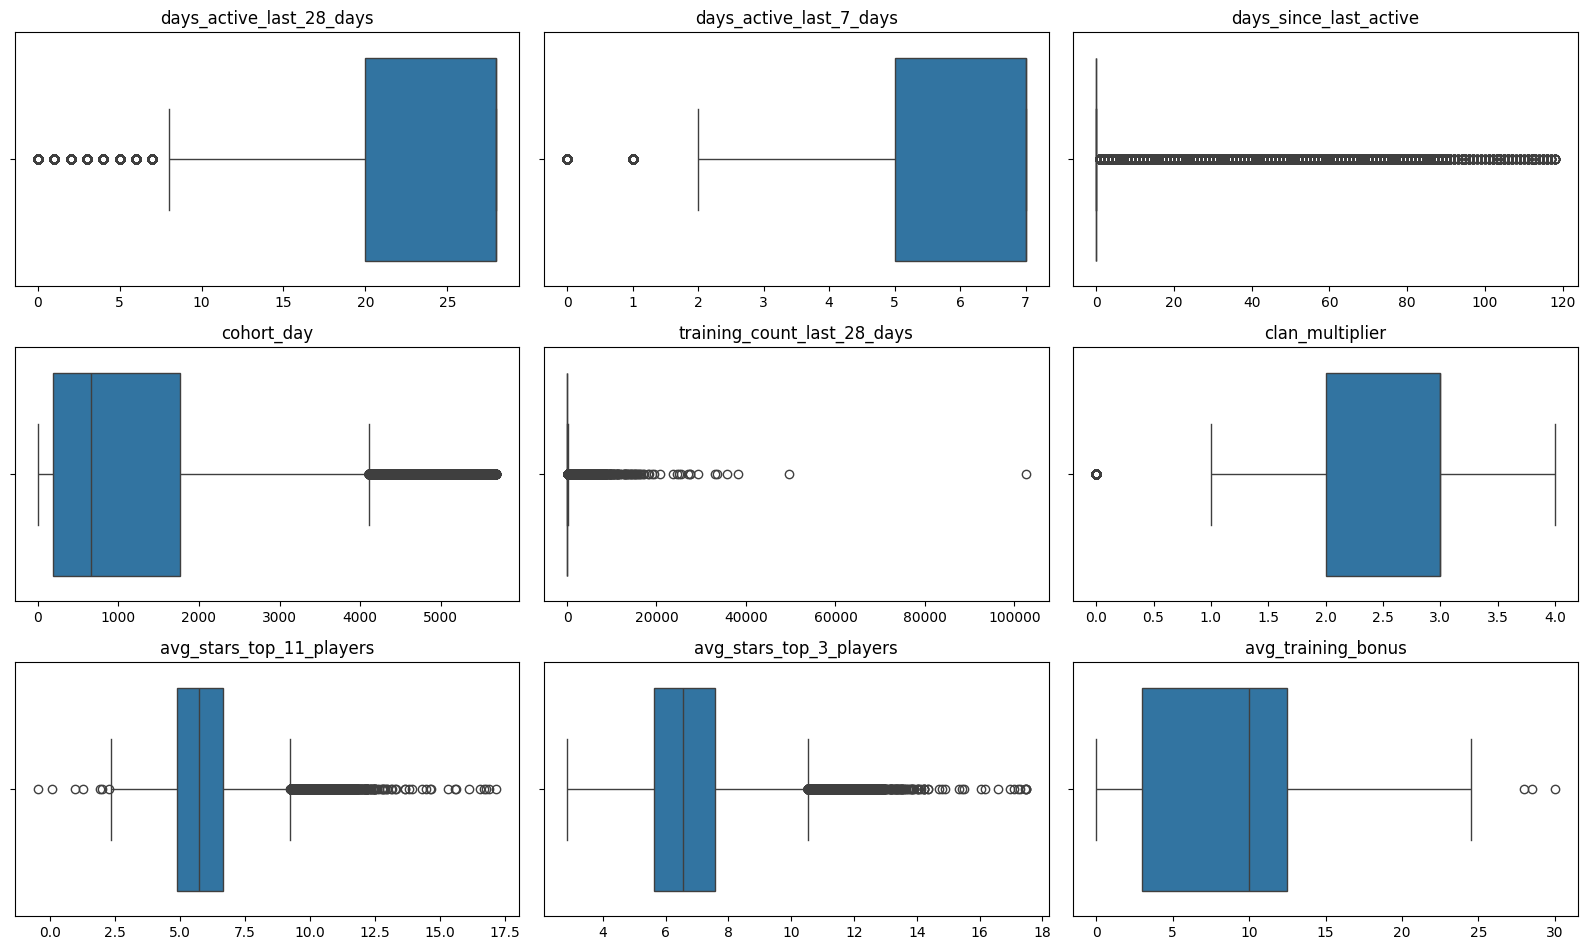

In [24]:
n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.2 * n_rows))
axes = axes.ravel()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=members[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")

for ax in axes[len(numeric_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Numeric correlations

Correlations here are at the member row level, not the match level. They are useful mostly for spotting redundant feature families before aggregation.


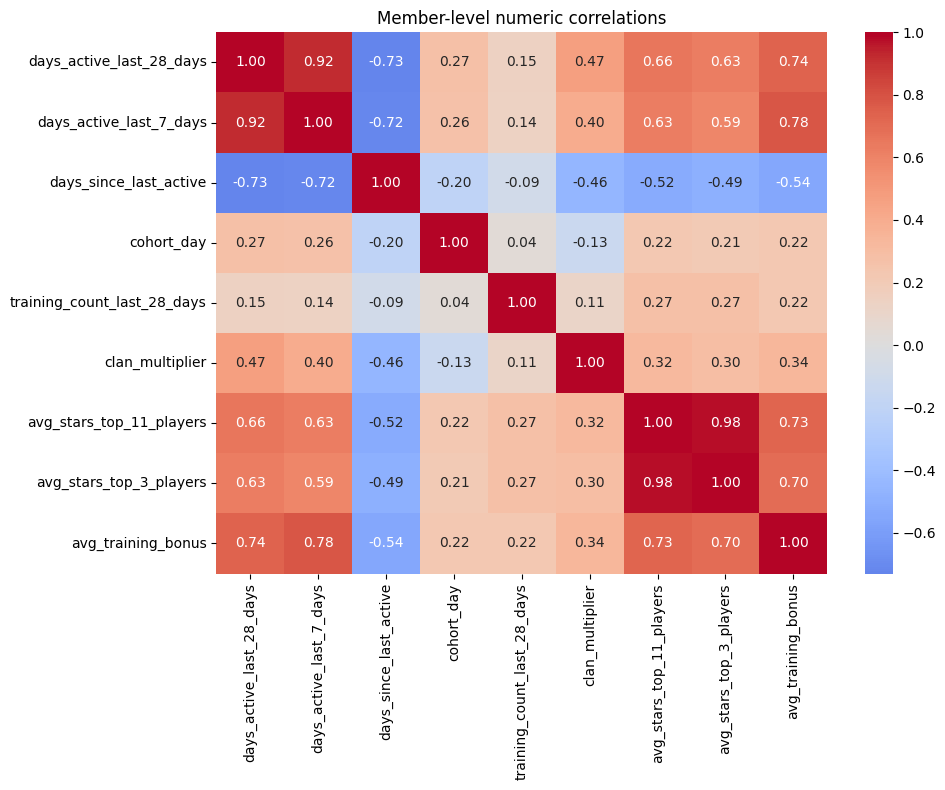

In [25]:
corr = members[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Member-level numeric correlations")
plt.tight_layout()
plt.show()


## Categorical fields



In [28]:
for col in categorical_cols + bool_cols:
    counts = members[col].value_counts(dropna=False)
    summary = (
        pd.DataFrame(
            {
                "count": counts,
                "share": counts / len(members),
            }
        )
        .sort_values("share", ascending=False)
    )

    print(f"\n{col} | unique values: {members[col].nunique(dropna=False)}")
    display(summary.head(20))


registration_country | unique values: 216


,count,share
registration_country,,
Indonesia,44218,0.151714
Turkey,20363,0.069866
Germany,19310,0.066254
Thailand,15543,0.053329
France,13344,0.045784
Italy,13140,0.045084
United Kingdom,9422,0.032327
Spain,9196,0.031552
Poland,8806,0.030214



registration_platform_specific | unique values: 11


,count,share
registration_platform_specific,,
Android Phone,185758,0.637345
iOS Phone,58927,0.202181
Flash FB Canvas,17190,0.058980
Android Tablet,9775,0.033539
iOS Tablet,7100,0.024360
WebGL FB Canvas,4825,0.016555
WebGL TE Site,3352,0.011501
UniversalWindows PC,3023,0.010372
WebGL or Flash FB Canvas,1025,0.003517



dynamic_payment_segment | unique values: 6


,count,share
dynamic_payment_segment,,
0) NonPayer,157727,0.541169
2) Minnow,51257,0.175865
1) ExPayer,50752,0.174133
3) Dolphin,22233,0.076283
4) Whale,9419,0.032317
Negative,68,0.000233



is_payer_lifetime | unique values: 2


,count,share
is_payer_lifetime,,
False,157727,0.541169
True,133729,0.458831
